# Label leakage in Al Isawi et al. (2025): a live demonstration

Run from the project root (needs the OTIDS logs in `data/raw/`). About one minute.

In [1]:
import sys, numpy as np, pandas as pd
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import chi2_contingency
from src.data.build_dataset import load_config, sample_dataset, make_split, _log
cfg = load_config()
NAMES = {0: 'DoS', 1: 'Impersonation', 2: 'Normal'}

## 1. What the paper says (Section III-B, p. 90867)

> *"The total number of inputs for all techniques is 10, which are the **CAN ID**, DLC, and the eight data field values."*

> *"The class labeling is done **based on the CAN ID** where an ID of '0×164' … corresponds to an 'Impersonation' attack class, an ID of '0×000' corresponds to a 'DOS' attack class, and the rest corresponds to the 'Normal' or benign class."*

So the label is a fixed function of one of the inputs: **label = f(CAN ID)**.

**For DoS this labelling is correct:** no real ECU uses 0x000, so every 0x000 frame really is injected (the ID just makes DoS trivial to detect). **For Impersonation it is not:** 0x164 is a legitimate ID, so the rule also labels the genuine ECU's frames as attacks. Sections 6–7 show this.

## 2. In the data: the CAN ID determines the label completely

A 20,000-frame sample built exactly as the paper describes (seed 0). Each CAN ID group maps to exactly one class: there are no off-diagonal entries.

In [2]:
df = sample_dataset('A', seed=0, cfg=cfg)
id_group = np.select([df.can_id == 0x000, df.can_id == 0x164], ['ID 0x000', 'ID 0x164'], 'any other ID')
pd.crosstab(pd.Series(id_group, name='CAN ID'), df.label.map(NAMES).rename('label'))

label,DoS,Impersonation,Normal
CAN ID,,,
ID 0x000,1497,0,0
ID 0x164,0,979,0
any other ID,0,0,17524


## 3. A one-line rule on the CAN ID alone is perfect

No learning and no payload: just `if ID == 0x000 → DoS; elif ID == 0x164 → Imp; else Normal`, applied to the paper-style test set.

In [3]:
sp = make_split('A', 'multi', seed=0, cfg=cfg)
ids = sp.X_test[:, sp.features.index('can_id')]
rule = np.where(ids == 0x000, 0, np.where(ids == 0x164, 1, 2))
print(f'rule on CAN ID only: accuracy = {accuracy_score(sp.y_test, rule):.4f}, '
      f'macro-F1 = {f1_score(sp.y_test, rule, average="macro"):.4f}  (paper ANFIS: 99.68 % accuracy)')

rule on CAN ID only: accuracy = 1.0000, macro-F1 = 1.0000  (paper ANFIS: 99.68 % accuracy)


## 4. Any model that can isolate an ID value learns this rule

A depth-3 decision tree trained on the **CAN ID alone** recovers the labelling rule as its splits. A linear model on the same single input cannot isolate the middle value 356 (0x164) with one threshold, which explains the paper's weak LDA/LR baselines.

In [4]:
Xtr_id = sp.X_train[:, [sp.features.index('can_id')]]
Xte_id = sp.X_test[:, [sp.features.index('can_id')]]
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr_id, sp.y_train)
print(f'decision tree, CAN ID only: macro-F1 = {f1_score(sp.y_test, tree.predict(Xte_id), average="macro"):.4f}')
print(export_text(tree, feature_names=['can_id'], class_names=list(NAMES.values())))
sc = MinMaxScaler().fit(Xtr_id)
lr = LogisticRegression(max_iter=2000).fit(sc.transform(Xtr_id), sp.y_train)
print(f'logistic regression, CAN ID only: macro-F1 = '
      f'{f1_score(sp.y_test, lr.predict(sc.transform(Xte_id)), average="macro"):.4f}  (one linear cut cannot isolate ID 356)')

decision tree, CAN ID only: macro-F1 = 1.0000
|--- can_id <= 12.00
|   |--- class: DoS
|--- can_id >  12.00
|   |--- can_id <= 356.50
|   |   |--- can_id <= 347.50
|   |   |   |--- class: Normal
|   |   |--- can_id >  347.50
|   |   |   |--- class: Impersonation
|   |--- can_id >  356.50
|   |   |--- class: Normal

logistic regression, CAN ID only: macro-F1 = 0.6476  (one linear cut cannot isolate ID 356)


## 5. Consequence: almost every model hits the ceiling, and removing the ID shows real differences

Macro-F1, multiclass, mean over 5 seeds, from the full study (`results/metrics_long.csv`). Setting A uses the paper's inputs; A-noID removes the CAN ID (and adds inter-arrival time).

In [5]:
m = pd.read_csv('results/metrics_long.csv')
m = m[(m.metric == 'macro_f1') & (m.variant == 'main') & (m.task == 'multi') & m.setting.isin(['A', 'A-noID'])]
t = m.astype({'value': float}).groupby(['model', 'setting']).value.mean().unstack().round(4)
t['drop without ID'] = (t['A-noID'] - t['A']).round(4)
print('models with macro-F1 >= 0.99 in Setting A:', int((t['A'] >= 0.99).sum()), 'of', len(t))
t.sort_values('A', ascending=False)

models with macro-F1 >= 0.99 in Setting A: 11 of 15


setting,A,A-noID,drop without ID
model,,,
ANFIS-FCM+stk,1.0000,0.9847,-0.0153
ANFIS-Random+stk,1.0000,0.9659,-0.0341
ANFIS-SC,1.0000,0.9832,-0.0168
RF,1.0000,0.9886,-0.0114
ANFIS-SC+stk,1.0000,0.9861,-0.0139
ANFIS-FCM,0.9993,0.9525,-0.0468
ANFIS-KMeans+stk,0.9986,0.9871,-0.0115
MLP,0.9979,0.9824,-0.0155
RBF-SVM,0.9971,0.9441,-0.0530


## 6. The rule labels normal driving as an attack

ID 0x164 is a **legitimate ECU message**: a car under no attack sends it all the time. Applying the paper's rule to the attack-free log flags all of those frames as 'Impersonation'.

In [6]:
af = _log('attack_free')
n164 = int((af.can_id == 0x164).sum())
print(f'attack-free log: {len(af):,} frames, {n164:,} with ID 0x164 = {n164 / len(af):.1%} of a clean drive '
      'that the paper\'s rule would call an attack')

attack-free log: 2,369,398 frames, 126,605 with ID 0x164 = 5.3% of a clean drive that the paper's rule would call an attack


## 7. In the impersonation log, attacker and genuine 0x164 frames look the same

HCRL documents that the attack starts at 250 s. If impersonation were visible in the frames, 0x164 traffic after 250 s should differ from before. It does not.

0x164 rate: before 119.2 Hz, after 118.9 Hz
mean gap:  before 8.39 ms, after 8.41 ms


payload patterns before vs after: chi2 = 3.6, dof = 17, p = 1.000  (p near 1 = same distribution)


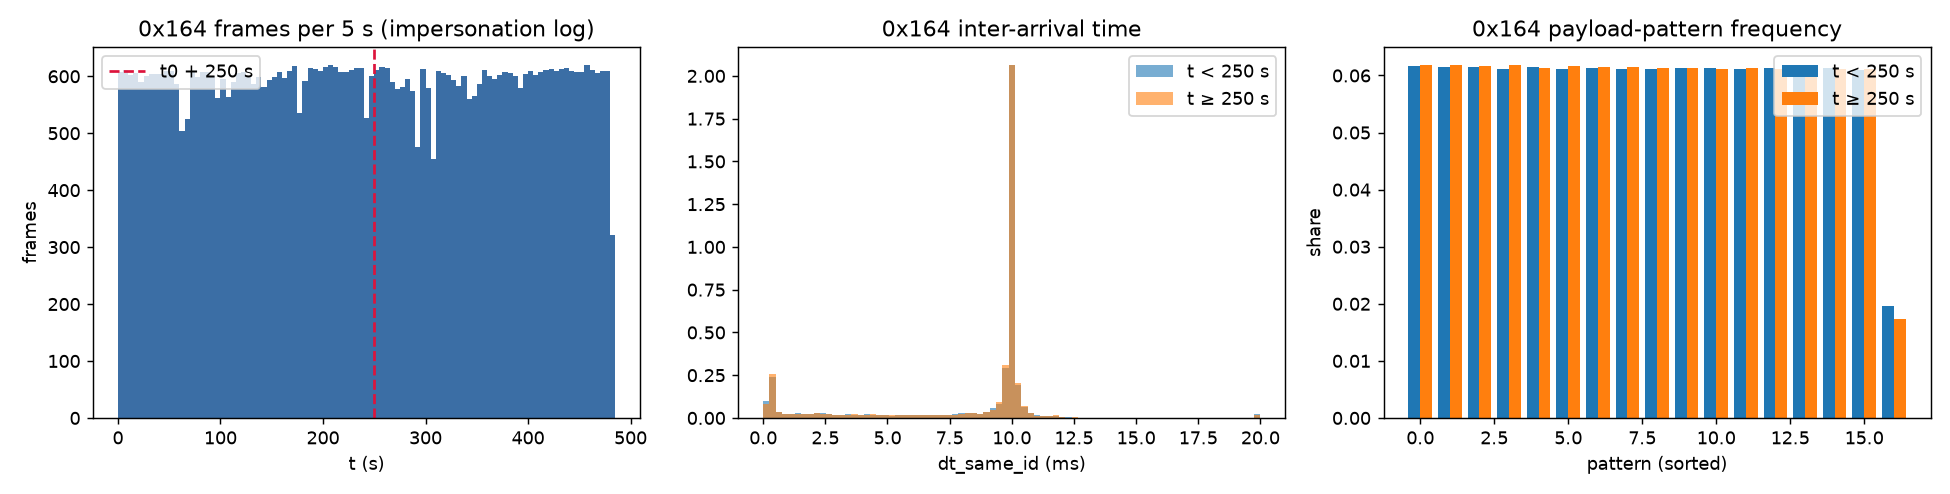

In [7]:
imp = _log('impersonation')
s = imp[imp.can_id == 0x164]
pre, post = s[s.t_rel < 250], s[s.t_rel >= 250]
rate = lambda x, dur: len(x) / dur
print(f'0x164 rate: before {rate(pre, 250):.1f} Hz, after {rate(post, imp.t_rel.max() - 250):.1f} Hz')
print(f'mean gap:  before {pre.dt_same_id.mean()*1e3:.2f} ms, after {post.dt_same_id.mean()*1e3:.2f} ms')
pay = lambda x: x[[f'd{i}' for i in range(8)]].astype(str).agg(' '.join, axis=1)
ct = pd.crosstab(pay(s), s.t_rel >= 250)
ct = ct[(ct.sum(axis=1) >= 20)]
chi2, p, dof, _ = chi2_contingency(ct)
print(f'payload patterns before vs after: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.3f}  (p near 1 = same distribution)')
from IPython.display import Image
Image('results/figures/data_impersonation_0x164.png', width=900)

## Conclusion

1. **In the paper:** the CAN ID is an input *and* the label is defined from the CAN ID (Section III-B).
2. **In the data:** the ID alone predicts the label perfectly; a 3-split tree recovers the rule; most models reach ≥ 0.99, so the ≈ 99.7 % headline does not show that ANFIS is needed.
3. **DoS: labels correct, detection trivial.** No real ECU uses 0x000.
4. **Impersonation: label leakage.** Genuine 0x164 traffic is labelled as an attack (5.3 % of a normal drive), and attacker frames are statistically identical to genuine ones, as the dataset's own documentation says (impersonation cannot be separated by ID). The paper's Impersonation result measures ID recognition, not attack detection.

This is why the project's main benchmark (A-noID) removes the CAN ID, and Setting B relabels impersonation by attack time.